# M6 — TabNet Employee Resignation Model

**Owner:** Member 6  
**Primary selection metric:** development out-of-fold average precision (PR-AUC)  
**Formal holdout status:** prohibited in this notebook

This notebook runs the frozen TabNet experiment contract. Category vocabularies, numerical imputation, and numerical scaling are learned inside each outer-training fold. The outer validation fold is used only for out-of-fold prediction; TabNet early stopping uses a stratified inner split created by the adapter.

## Individual preprocessing and parameter comparison

The formal eight-candidate strict-nested OOF remains the group input. This **short exploratory check** used the same 5,000/2,000 development split and five-epoch cap. T01/T02 share architecture and learning rate; T02 changes class balancing. Salary is either retained or masked at the training-only median.

| Input preparation | T01 AP, unweighted | T02 AP, balanced |
|---|---:|---:|
| All 17 predictors | 0.098768 | 0.105518 |
| Salary masked at training median | 0.109992 | 0.108103 |

This single sample does not establish that salary masking helps. Full metrics, validation and limitations are in [Individual model evidence](../../../../reports/INDIVIDUAL_MODEL_EVIDENCE.md).


In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)

def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "configs" / "feature_contract.yaml").exists() and (candidate / "data" / "processed" / "split_registry.csv").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate repository root from the current working directory.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.metrics import calculate_binary_metrics
from src.models.runner import run_5fold_cv
from src.models.tabnet_model import TabNetAdapter, load_tabnet_config

CONFIG = load_tabnet_config(PROJECT_ROOT / "configs" / "models" / "tabnet.yaml")
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"
REGISTRY_PATH = PROJECT_ROOT / "data" / "processed" / "split_registry.csv"
OUTPUT_DIR = PROJECT_ROOT / "results" / "models" / "tabnet"
# Keep the frozen 17-feature contract; ID, raw hire date and target stay outside X.
FEATURES = CONFIG["preprocessing"]["categorical_features"] + CONFIG["preprocessing"]["numerical_features"]
TARGET = "Resigned"
ID_COLUMN = "Employee_ID"

print(f"Project root: {PROJECT_ROOT}")
print(f"TabNet candidates: {[item['id'] for item in CONFIG['candidates']]}")

Project root: C:\Users\Kawya\Documents\AIML Project
TabNet candidates: ['T01', 'T02', 'T03', 'T04', 'T05', 'T06', 'T07', 'T08']


## HISTORICAL / EXPLORATORY TabNet candidate results

The existing T01–T08 pooled OOF comparison and T01 seed-sensitivity outputs are retained as **HISTORICAL / EXPLORATORY** evidence only. They are displayed but are not used to choose the final TabNet configuration. Final headline evidence requires independent inner candidate and epoch selection inside every frozen outer-training fold. The formal holdout remains prohibited.

In [2]:
HISTORICAL_REFERENCE_CANDIDATE = "T01"
SELECTION_DIR = OUTPUT_DIR / "selection"
SEED_DIR = OUTPUT_DIR / "seed_sensitivity"

raw = pd.read_csv(RAW_PATH)
registry = pd.read_csv(REGISTRY_PATH, dtype={"cv_fold": "Int64"})
development_registry = registry.loc[
    registry["partition"] == "development", [ID_COLUMN, "cv_fold"]
].copy()
holdout_ids = set(registry.loc[registry["partition"] == "holdout", ID_COLUMN])
development = raw.merge(
    development_registry, on=ID_COLUMN, how="inner", validate="one_to_one"
)
assert len(development) == 80_000
assert set(development[ID_COLUMN]).isdisjoint(holdout_ids)
assert sorted(development["cv_fold"].astype(int).unique().tolist()) == [1, 2, 3, 4, 5]

candidate_rows = []
for candidate_path in sorted(OUTPUT_DIR.glob("t??")):
    summary_path = candidate_path / "summary_metrics.json"
    if summary_path.exists():
        summary = json.loads(summary_path.read_text(encoding="utf-8"))
        candidate_rows.append({"candidate": candidate_path.name.upper(), **summary})

historical_candidate_comparison = pd.DataFrame(candidate_rows).sort_values(
    "pooled_average_precision", ascending=False
).reset_index(drop=True)
assert len(historical_candidate_comparison) == 8
print("HISTORICAL / EXPLORATORY ONLY — not final candidate-selection evidence.")
display(historical_candidate_comparison[[
    "candidate", "pooled_average_precision", "cv_mean_average_precision",
    "cv_std_average_precision", "pooled_roc_auc", "pooled_brier_score",
    "total_fit_time_seconds",
]])

historical_seed_path = SELECTION_DIR / "seed_sensitivity.csv"
historical_summary_path = SELECTION_DIR / "selection_summary.json"
if historical_seed_path.exists():
    display(pd.read_csv(historical_seed_path))
if historical_summary_path.exists():
    historical_summary = json.loads(historical_summary_path.read_text(encoding="utf-8"))
    display(pd.Series(historical_summary, name="historical_exploratory_selection"))

HISTORICAL / EXPLORATORY ONLY — not final candidate-selection evidence.


,candidate,pooled_average_precision,cv_mean_average_precision,cv_std_average_precision,pooled_roc_auc,pooled_brier_score,total_fit_time_seconds
0,T01,0.101706,0.101955,0.001801,0.504556,0.090267,504.668862
1,T02,0.100757,0.102074,0.004120,0.500338,0.253767,586.403368
2,T05,0.100672,0.100980,0.001187,0.501184,0.091430,234.304518
3,T08,0.100571,0.101575,0.001304,0.502327,0.251642,2107.993343
4,T04,0.100564,0.100444,0.002337,0.499674,0.248368,848.018646
5,T06,0.100555,0.100486,0.001026,0.503286,0.261512,780.774142
6,T07,0.100503,0.100238,0.001818,0.500173,0.090800,3440.982471
7,T03,0.100487,0.100702,0.001586,0.501749,0.090404,511.405817


,random_seed,model_name,model_id,total_development_records,total_folds,pooled_average_precision,pooled_roc_auc,pooled_f1,pooled_brier_score,cv_mean_average_precision,cv_std_average_precision,cv_mean_roc_auc,cv_std_roc_auc,cv_mean_f1,cv_std_f1,total_fit_time_seconds,total_predict_time_seconds
0,7,TabNet,tabnet,80000,5,0.099065,0.496543,0.0,0.090455,0.099840,0.003320,0.498376,0.011322,0.0,0.0,1768.516028,2.403747
1,42,TabNet,tabnet,80000,5,0.101706,0.504556,0.0,0.090267,0.101955,0.001801,0.504222,0.003158,0.0,0.0,504.668862,1.531174
2,2026,TabNet,tabnet,80000,5,0.101108,0.502297,0.0,0.090325,0.101471,0.001221,0.503275,0.004732,0.0,0.0,772.750394,1.730221


selection_metric                              pooled_average_precision
selected_candidate                                                 T01
primary_comparison_seed                                             42
additional_sensitivity_seeds                                 [7, 2026]
seed_count                                                           3
mean_pooled_average_precision_across_seeds                    0.100626
std_pooled_average_precision_across_seeds                     0.001131
min_pooled_average_precision_across_seeds                     0.099065
max_pooled_average_precision_across_seeds                     0.101706
formal_holdout_used                                              False
Name: historical_exploratory_selection, dtype: object

## 1. Load only the frozen development partition

The registry—not a new random split—defines the 80,000 development rows and five shared folds. This cell explicitly checks that no formal-holdout employee enters the modelling dataframe.

**Feature contract:** X contains 17 predictors (4 categorical and 13 numerical). `Employee_ID` and raw `Hire_Date` are excluded, while `Resigned` is separated as y.

In [3]:
raw = pd.read_csv(RAW_PATH)
registry = pd.read_csv(REGISTRY_PATH)

development_registry = registry.loc[registry["partition"] == "development", [ID_COLUMN, "cv_fold"]].copy()
holdout_ids = set(registry.loc[registry["partition"] == "holdout", ID_COLUMN])
development = raw.merge(development_registry, on=ID_COLUMN, how="inner", validate="one_to_one")

print(f"Raw shape: {raw.shape}")
print(f"Development shape after registry filtering: {development.shape}")
assert len(development) == 80_000
# Formal holdout IDs must never enter training, tuning or OOF evaluation.
assert set(development[ID_COLUMN]).isdisjoint(holdout_ids)
assert sorted(development["cv_fold"].unique().tolist()) == [1, 2, 3, 4, 5]
assert set(FEATURES).issubset(development.columns)
assert ID_COLUMN not in FEATURES and "Hire_Date" not in FEATURES and TARGET not in FEATURES

target_summary = development[TARGET].value_counts(dropna=False).rename_axis(TARGET).to_frame("count")
target_summary["proportion"] = target_summary["count"] / len(development)
display(target_summary)

Raw shape: (100000, 20)
Development shape after registry filtering: (80000, 21)


,count,proportion
Resigned,,
False,71992,0.8999
True,8008,0.1001


## 2. Dependency and save/reload smoke test

This development-only diagnostic samples 5,000 records from the training side of outer fold 1, then creates 4,000 smoke-training and 1,000 smoke-validation records. It never reads the formal holdout or outer fold 1 validation rows. These metrics are not formal model results. The save/reload assertion verifies that serialized preprocessing and model parameters reproduce probabilities.

In [4]:
RUN_SMOKE_TEST = False

if RUN_SMOKE_TEST:
    smoke_config = CONFIG["smoke_test"]
    outer_training = development.loc[development["cv_fold"] != 1].reset_index(drop=True)
    smoke_pool_idx, _ = train_test_split(
        np.arange(len(outer_training)),
        train_size=int(smoke_config["sample_rows"]),
        random_state=int(CONFIG["training"]["random_seed"]),
        stratify=outer_training[TARGET],
    )
    smoke_pool = outer_training.iloc[smoke_pool_idx].reset_index(drop=True)
    smoke_train, smoke_valid = train_test_split(
        smoke_pool,
        train_size=4_000,
        test_size=1_000,
        random_state=int(CONFIG["training"]["random_seed"]),
        stratify=smoke_pool[TARGET],
    )
    smoke_train = smoke_train.reset_index(drop=True)
    smoke_valid = smoke_valid.reset_index(drop=True)

    assert len(FEATURES) == 17
    assert len(CONFIG["preprocessing"]["categorical_features"]) == 4
    assert len(CONFIG["preprocessing"]["numerical_features"]) == 13
    assert {ID_COLUMN, "Hire_Date", TARGET}.isdisjoint(FEATURES)
    assert CONFIG["training"]["cat_emb_dim"] == 1
    assert set(smoke_train[ID_COLUMN]).isdisjoint(holdout_ids)
    assert set(smoke_valid[ID_COLUMN]).isdisjoint(holdout_ids)
    assert (smoke_train["cv_fold"] != 1).all() and (smoke_valid["cv_fold"] != 1).all()
    assert set(smoke_train[ID_COLUMN]).isdisjoint(set(smoke_valid[ID_COLUMN]))
    print(f"Smoke source shape: {outer_training.shape}")
    print(f"Smoke train / validation: {smoke_train.shape} / {smoke_valid.shape}")

    smoke_adapter = TabNetAdapter(
        config=CONFIG,
        candidate_id=smoke_config["candidate_id"],
        max_epochs_override=int(smoke_config["max_epochs"]),
        patience_override=int(smoke_config["patience"]),
    )
    smoke_adapter.fit(smoke_train[FEATURES], smoke_train[TARGET])
    smoke_probability = smoke_adapter.predict_proba(smoke_valid[FEATURES])
    assert len(smoke_probability) == 1_000
    assert np.isfinite(smoke_probability).all()
    assert ((smoke_probability >= 0.0) & (smoke_probability <= 1.0)).all()
    assert smoke_adapter.preprocessor is not None
    assert len(smoke_adapter.preprocessor.category_mappings) == 4
    assert smoke_adapter.selected_epoch is not None
    smoke_metrics = calculate_binary_metrics(smoke_valid[TARGET].astype(int), smoke_probability)
    display(pd.Series(smoke_metrics, name="diagnostic_smoke_metric"))

    smoke_artifact_dir = OUTPUT_DIR / "smoke_artifact"
    # Save/reload keeps the fold-fitted preprocessing and model parameters together.
    smoke_adapter.save(smoke_artifact_dir)
    reloaded_adapter = TabNetAdapter.load(smoke_artifact_dir)
    reloaded_probability = reloaded_adapter.predict_proba(smoke_valid[FEATURES])
    np.testing.assert_allclose(smoke_probability, reloaded_probability, rtol=1e-6, atol=1e-7)
    maximum_absolute_difference = float(np.max(np.abs(smoke_probability - reloaded_probability)))
    smoke_verification = {
        "predictions_match": True,
        "maximum_absolute_difference": maximum_absolute_difference,
        "prediction_count": int(len(smoke_probability)),
        "selected_candidate_id": smoke_adapter.candidate_id,
        "selected_epoch": int(smoke_adapter.selected_epoch),
        "configuration_version": CONFIG["model"]["config_version"],
        "project_context_version": CONFIG["model"]["project_context_version"],
        "cat_emb_dim": int(CONFIG["training"]["cat_emb_dim"]),
        "feature_count": int(len(FEATURES)),
        "categorical_feature_count": int(len(CONFIG["preprocessing"]["categorical_features"])),
        "numerical_feature_count": int(len(CONFIG["preprocessing"]["numerical_features"])),
        "smoke_training_rows": int(len(smoke_train)),
        "smoke_validation_rows": int(len(smoke_valid)),
        "holdout_overlap": 0,
        "formal_holdout_used": False,
        "rtol": 1e-6,
        "atol": 1e-7,
    }
    (OUTPUT_DIR / "smoke_verification.json").write_text(
        json.dumps(smoke_verification, indent=2), encoding="utf-8"
    )
    display(pd.Series(smoke_verification, name="smoke_verification"))
    print("Smoke fit, prediction, serialization, and reload checks passed.")
else:
    print("Smoke training is disabled. Set RUN_SMOKE_TEST=True only after dependency approval.")

Smoke training is disabled. Set RUN_SMOKE_TEST=True only after dependency approval.


## 3. STRICT NESTED DEVELOPMENT OOF RESULTS — completed run

The saved outputs below are the completed formal strict-nested development run. One automatic-selection adapter per outer fold evaluated T01–T08 on a training-only inner split, selected the candidate and epoch by inner Average Precision, refitted the winner on all outer-training rows, and predicted the untouched outer-validation fold. Historical pooled candidate results were not used. The formal holdout was not opened, scored, or predicted. The expensive-run guard is now disabled by default; the preserved outputs document the validated run.

**Nested split to remember:** each fold has 64,000 outer-training rows, divided into 56,000 inner-training and 8,000 inner-validation rows; the remaining 16,000 outer-validation rows are prediction-only after the winner is fixed.

**Metric interpretation:** Average Precision (PR-AUC) is primary because resignation is the minority class. ROC-AUC also measures ranking across thresholds, while Brier score measures probability accuracy (lower is better).

In [5]:
RUN_FORMAL_CV = False
if RUN_FORMAL_CV:
    fitted_outer_adapters = []

    def make_nested_adapter():
        outer_fold = len(fitted_outer_adapters) + 1
        adapter = TabNetAdapter(
            config=CONFIG, candidate_id="auto", outer_fold=outer_fold
        )
        fitted_outer_adapters.append(adapter)
        return adapter

    # Each outer fold trains on 64k rows and predicts only its untouched 16k rows.
    result = run_5fold_cv(
        adapter_factory=make_nested_adapter,
        data=development.drop(columns=["cv_fold"]),
        split_registry=registry,
        feature_cols=FEATURES,
        target_col=TARGET,
        expected_model_name="TabNet",
    )
    assert len(fitted_outer_adapters) == 5
    fold_selection_rows = []
    candidate_selection_rows = []
    history_dir = OUTPUT_DIR / "training_histories"
    history_dir.mkdir(parents=True, exist_ok=True)
    model_dir = PROJECT_ROOT / "models" / "tabnet" / "outer_folds"

    for adapter in fitted_outer_adapters:
        metadata = adapter.get_metadata()
        fold = int(metadata["outer_fold"])
        outer_metrics = result.fold_metrics.loc[result.fold_metrics["fold"] == fold].iloc[0]
        history_path = history_dir / f"fold_{fold:02d}.json"
        fold_selection_rows.append({
            "outer_fold": fold,
            "selected_candidate_id": metadata["selected_candidate_id"],
            "selected_candidate_parameters": json.dumps(metadata["selected_candidate_parameters"], sort_keys=True),
            "selected_epoch": metadata["selected_epoch"],
            "best_inner_average_precision": metadata["best_inner_average_precision"],
            "outer_average_precision": float(outer_metrics["average_precision"]),
            "outer_roc_auc": float(outer_metrics["roc_auc"]),
            "outer_brier_score": float(outer_metrics["brier_score"]),
            "outer_f1": float(outer_metrics["f1"]),
            "outer_balanced_accuracy": float(outer_metrics["balanced_accuracy"]),
            "outer_precision": float(outer_metrics["precision"]),
            "outer_recall": float(outer_metrics["recall"]),
            "outer_validation_rows": 16000,
            "prediction_time_seconds": float(outer_metrics["predict_time_seconds"]),
            "seed": metadata["seed"],
            "class_balance": metadata["class_balance"],
            "configuration_version": metadata["config_version"],
            **metadata["fit_summary"],
        })
        inner_split_id = f"outer_fold_{fold:02d}_seed_{metadata['seed']}"
        for candidate_record in metadata["candidate_selection_records"]:
            candidate_row = {"outer_fold": fold, **candidate_record}
            candidate_row["candidate_parameters"] = json.dumps(candidate_record["candidate_parameters"], sort_keys=True)
            candidate_row["training_status"] = "success" if candidate_record["success"] else "failed"
            candidate_row["inner_split_id"] = inner_split_id
            candidate_row["inner_training_rows"] = metadata["fit_summary"]["inner_training_rows"]
            candidate_row["inner_validation_rows"] = metadata["fit_summary"]["inner_validation_rows"]
            candidate_row["training_history_reference"] = str(history_path.relative_to(PROJECT_ROOT)) + f"#{candidate_record['candidate_id']}"
            candidate_selection_rows.append(candidate_row)
        history_path.write_text(
            json.dumps(metadata["training_histories"], indent=2), encoding="utf-8"
        )
        adapter.save(model_dir / f"fold_{fold:02d}")

    fold_selection = pd.DataFrame(fold_selection_rows).sort_values("outer_fold").reset_index(drop=True)
    candidate_selection = pd.DataFrame(candidate_selection_rows).sort_values(["outer_fold", "candidate_id"]).reset_index(drop=True)
    predictions = result.predictions.sort_values(["cv_fold", ID_COLUMN]).reset_index(drop=True)
    fold_metrics = result.fold_metrics.sort_values("fold").reset_index(drop=True)

    assert len(fold_selection) == 5 and fold_selection["outer_fold"].tolist() == [1, 2, 3, 4, 5]
    assert len(candidate_selection) == 40
    assert not candidate_selection.duplicated(["outer_fold", "candidate_id"]).any()
    expected_candidates = {f"T{i:02d}" for i in range(1, 9)}
    for fold in range(1, 6):
        fold_candidates = candidate_selection.loc[candidate_selection["outer_fold"] == fold]
        assert set(fold_candidates["candidate_id"]) == expected_candidates
        assert fold_candidates["inner_split_id"].nunique() == 1
        assert set(fold_candidates["inner_training_rows"]) == {56000}
        assert set(fold_candidates["inner_validation_rows"]) == {8000}
    # Five untouched outer-fold predictions give one OOF probability per development row.
    assert len(predictions) == 80000 and predictions[ID_COLUMN].nunique() == 80000
    assert predictions[ID_COLUMN].is_unique
    assert predictions["cv_fold"].value_counts().sort_index().tolist() == [16000] * 5
    assert set(predictions["cv_fold"].astype(int)) == {1, 2, 3, 4, 5}
    assert predictions["y_probability"].notna().all() and np.isfinite(predictions["y_probability"]).all()
    assert predictions["y_probability"].between(0.0, 1.0).all()
    assert set(predictions["y_true"].astype(int)) <= {0, 1}
    assert set(predictions[ID_COLUMN]).isdisjoint(holdout_ids)
    frozen_folds = registry.loc[registry["partition"] == "development", [ID_COLUMN, "cv_fold"]].copy()
    fold_audit = predictions[[ID_COLUMN, "cv_fold"]].merge(frozen_folds, on=ID_COLUMN, validate="one_to_one", suffixes=("_oof", "_registry"))
    assert len(fold_audit) == 80000
    assert (fold_audit["cv_fold_oof"].astype(int) == fold_audit["cv_fold_registry"].astype(int)).all()

    # AP is primary; ROC-AUC and Brier add ranking and probability-quality views.
    summary_metrics = dict(result.summary_metrics)
    summary_metrics.update({
        "result_label": "STRICT NESTED DEVELOPMENT OOF RESULTS",
        "config_version": CONFIG["model"]["config_version"],
        "project_context_version": CONFIG["model"]["project_context_version"],
        "candidate_evaluations": 40,
        "outer_winner_refits": 5,
        "formal_holdout_used": False,
        "formal_holdout_overlap": 0,
    })
    runtime_efficiency = fold_selection[["outer_fold", "selected_candidate_id", "selected_epoch", "candidate_selection_time_seconds", "refit_time_seconds", "fit_time_seconds", "prediction_time_seconds"]].copy()
    run_metadata = {
        "result_label": "STRICT NESTED DEVELOPMENT OOF RESULTS",
        "protocol": "five-fold strict nested cross-validation",
        "student_id": "IT25100445",
        "model": "TabNet",
        "config_version": CONFIG["model"]["config_version"],
        "project_context_version": CONFIG["model"]["project_context_version"],
        "seed": int(CONFIG["training"]["random_seed"]),
        "candidate_ids": sorted(expected_candidates),
        "feature_count": len(FEATURES),
        "categorical_feature_count": len(CONFIG["preprocessing"]["categorical_features"]),
        "numerical_feature_count": len(CONFIG["preprocessing"]["numerical_features"]),
        "excluded_from_x": [ID_COLUMN, "Hire_Date", TARGET],
        "target": TARGET,
        "development_rows": 80000,
        "outer_folds": 5,
        "outer_training_rows_per_fold": 64000,
        "outer_validation_rows_per_fold": 16000,
        "inner_training_rows_per_fold": 56000,
        "inner_validation_rows_per_fold": 8000,
        "candidate_evaluations": 40,
        "outer_winner_refits": 5,
        "selection_metric": "inner validation average precision",
        "tie_breaker": "candidate ID ascending",
        "outer_validation_role": "prediction only after selection and refit",
        "formal_holdout_rows_used_for_training": 0,
        "formal_holdout_rows_used_for_inner_validation": 0,
        "formal_holdout_rows_used_for_outer_validation": 0,
        "formal_holdout_rows_used_for_preprocessing_fit": 0,
        "formal_holdout_rows_used_for_candidate_selection": 0,
        "formal_holdout_rows_used_for_epoch_selection": 0,
        "final_80000_row_model_trained": False,
        "additional_seed_runs_performed": False,
    }

    predictions.to_csv(OUTPUT_DIR / "oof_predictions.csv", index=False)
    fold_metrics.to_csv(OUTPUT_DIR / "fold_metrics.csv", index=False)
    (OUTPUT_DIR / "summary_metrics.json").write_text(
        json.dumps(summary_metrics, indent=2), encoding="utf-8"
    )
    fold_selection.to_csv(OUTPUT_DIR / "fold_selection.csv", index=False)
    candidate_selection.to_csv(OUTPUT_DIR / "candidate_selection.csv", index=False)
    runtime_efficiency.to_csv(OUTPUT_DIR / "runtime_efficiency.csv", index=False)
    (OUTPUT_DIR / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2), encoding="utf-8")
    manifest_paths = [
        OUTPUT_DIR / "oof_predictions.csv", OUTPUT_DIR / "fold_metrics.csv",
        OUTPUT_DIR / "summary_metrics.json", OUTPUT_DIR / "fold_selection.csv",
        OUTPUT_DIR / "candidate_selection.csv", OUTPUT_DIR / "runtime_efficiency.csv",
        OUTPUT_DIR / "run_metadata.json",
        *sorted(history_dir.glob("fold_*.json")),
    ]
    output_manifest = pd.DataFrame([{
        "artifact": str(path.relative_to(PROJECT_ROOT)),
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else None,
    } for path in manifest_paths])
    assert output_manifest["exists"].all()
    output_manifest.to_csv(OUTPUT_DIR / "output_manifest.csv", index=False)
    display(fold_metrics)
    display(fold_selection)
    display(pd.Series(summary_metrics, name="STRICT NESTED DEVELOPMENT OOF RESULTS"))
    print("Formal validation passed: 40 candidate evaluations, five winner refits, and 80,000 unique OOF predictions.")
else:
    print("RUN_FORMAL_CV is False: preserved formal outputs are not being regenerated.")

C:\Users\Kawya\Documents\AIML Project\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.38871 | inner_valid_average_precision: 0.10912 |  0:00:06s


epoch 1  | loss: 0.32764 | inner_valid_average_precision: 0.10211 |  0:00:12s


epoch 2  | loss: 0.32686 | inner_valid_average_precision: 0.09511 |  0:00:18s


epoch 3  | loss: 0.32658 | inner_valid_average_precision: 0.10537 |  0:00:24s


epoch 4  | loss: 0.32626 | inner_valid_average_precision: 0.10131 |  0:00:31s


... (1,148 outputs left out)

,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate,fold,fit_time_seconds,predict_time_seconds,pr_auc
0,0.097812,0.493657,0.098588,0.527795,0.166142,0.495615,0.469875,0.246222,6673,7726,756,845,8571,0.535687,1,1805.984590,0.509193,0.097812
1,0.102024,0.501126,0.099667,0.467208,0.164287,0.498970,0.524375,0.248711,7642,6757,853,748,7505,0.469062,2,1074.847551,0.745066,0.102024
2,0.100511,0.499974,0.000000,0.000000,0.000000,0.500000,0.899875,0.090201,14398,0,1602,0,0,0.000000,3,1432.859644,0.238088,0.100511
3,0.108087,0.515507,0.250000,0.001248,0.002484,0.500416,0.899625,0.090473,14392,6,1600,2,8,0.000500,4,769.051830,0.706331,0.108087
4,0.100067,0.495447,0.097351,0.451935,0.160195,0.492845,0.525563,0.255280,7685,6713,878,724,7437,0.464813,5,1107.052423,0.502487,0.100067


,outer_fold,selected_candidate_id,selected_candidate_parameters,selected_epoch,best_inner_average_precision,outer_average_precision,outer_roc_auc,outer_brier_score,outer_f1,outer_balanced_accuracy,outer_precision,outer_recall,outer_validation_rows,prediction_time_seconds,seed,class_balance,configuration_version,outer_training_rows_before,outer_training_rows_after,inner_training_rows,inner_validation_rows,positive_rate_outer_training,positive_rate_inner_training,positive_rate_inner_validation,candidate_count,candidate_selection_time_seconds,refit_time_seconds,fit_time_seconds
0,1,T02,"{""batch_size"": 1024, ""class_balance"": true, ""g...",33,0.110436,0.097812,0.493657,0.246222,0.166142,0.495615,0.098588,0.527795,16000,0.509193,42,True,2.0.0,64000,64000,56000,8000,0.100109,0.100107,0.100125,8,1574.333974,231.585796,1805.920773
1,2,T06,"{""batch_size"": 2048, ""class_balance"": true, ""g...",7,0.111033,0.102024,0.501126,0.248711,0.164287,0.498970,0.099667,0.467208,16000,0.745066,42,True,2.0.0,64000,64000,56000,8000,0.100109,0.100107,0.100125,8,1019.693330,55.124946,1074.818962
2,3,T01,"{""batch_size"": 1024, ""class_balance"": false, ""...",20,0.110610,0.100511,0.499974,0.090201,0.000000,0.500000,0.000000,0.000000,16000,0.238088,42,False,2.0.0,64000,64000,56000,8000,0.100094,0.100089,0.100125,8,1379.960074,52.846152,1432.806553
3,4,T07,"{""batch_size"": 1024, ""class_balance"": false, ""...",4,0.109632,0.108087,0.515507,0.090473,0.002484,0.500416,0.250000,0.001248,16000,0.706331,42,False,2.0.0,64000,64000,56000,8000,0.100094,0.100089,0.100125,8,735.505413,33.529286,769.035378
4,5,T06,"{""batch_size"": 2048, ""class_balance"": true, ""g...",2,0.111267,0.100067,0.495447,0.255280,0.160195,0.492845,0.097351,0.451935,16000,0.502487,42,True,2.0.0,64000,64000,56000,8000,0.100094,0.100089,0.100125,8,1095.117798,11.909362,1107.027651


model_name                                                   TabNet
model_id                                                     tabnet
total_development_records                                     80000
total_folds                                                       5
pooled_average_precision                                   0.099965
pooled_pr_auc                                              0.099965
pooled_roc_auc                                             0.499317
pooled_f1                                                  0.147103
pooled_brier_score                                         0.186177
cv_mean_average_precision                                    0.1017
cv_std_average_precision                                   0.003876
cv_mean_pr_auc                                               0.1017
cv_std_pr_auc                                              0.003876
cv_mean_roc_auc                                            0.501142
cv_std_roc_auc                                  

Formal validation passed: 40 candidate evaluations, five winner refits, and 80,000 unique OOF predictions.


## Formal TabNet repository checkpoint

The saved notebook outputs and `results/models/tabnet/` artifacts record the validated formal strict-nested development run: five outer folds, 40 inner candidate evaluations, five outer winner refits, and 80,000 OOF predictions. The formal holdout remained untouched, no additional seed runs were performed, and no final 80,000-row model was fitted. `RUN_FORMAL_CV` is intentionally reset to `False` after the run so reopening or running ordinary lightweight cells cannot accidentally repeat the expensive evaluation.

## Visualizations — Saved Formal Results Only

These plots use already-saved formal development results only. No training, tuning, candidate selection, OOF generation, or formal-holdout evaluation is performed here.

In [7]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_viva_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "results" / "models" / "tabnet" / "summary_metrics.json").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the saved formal TabNet results.")

VIVA_PROJECT_ROOT = find_viva_project_root()
VIVA_RESULTS_DIR = VIVA_PROJECT_ROOT / "results" / "models" / "tabnet"
viva_oof = pd.read_csv(VIVA_RESULTS_DIR / "oof_predictions.csv")
viva_fold_selection = pd.read_csv(VIVA_RESULTS_DIR / "fold_selection.csv")
viva_candidate_selection = pd.read_csv(VIVA_RESULTS_DIR / "candidate_selection.csv")
viva_fold_metrics = pd.read_csv(VIVA_RESULTS_DIR / "fold_metrics.csv")
viva_runtime = pd.read_csv(VIVA_RESULTS_DIR / "runtime_efficiency.csv")
viva_summary = json.loads((VIVA_RESULTS_DIR / "summary_metrics.json").read_text(encoding="utf-8"))
viva_run_metadata = json.loads((VIVA_RESULTS_DIR / "run_metadata.json").read_text(encoding="utf-8"))

assert viva_oof.shape == (80_000, 6)
assert viva_oof["Employee_ID"].is_unique
assert len(viva_fold_selection) == 5
assert len(viva_candidate_selection) == 40
assert viva_candidate_selection.groupby("outer_fold")["candidate_id"].nunique().eq(8).all()
assert viva_candidate_selection.groupby("outer_fold")["inner_split_id"].nunique().eq(1).all()
assert viva_summary["formal_holdout_used"] is False
assert viva_summary["formal_holdout_overlap"] == 0
holdout_audit_keys = [
    "formal_holdout_rows_used_for_training",
    "formal_holdout_rows_used_for_inner_validation",
    "formal_holdout_rows_used_for_outer_validation",
    "formal_holdout_rows_used_for_preprocessing_fit",
    "formal_holdout_rows_used_for_candidate_selection",
    "formal_holdout_rows_used_for_epoch_selection",
]
assert all(viva_run_metadata[key] == 0 for key in holdout_audit_keys)
print("Loaded saved formal development artifacts only: 80,000 OOF rows and 40 candidate evaluations.")

Loaded saved formal development artifacts only: 80,000 OOF rows and 40 candidate evaluations.


### Visual 1 — Strict nested-CV workflow

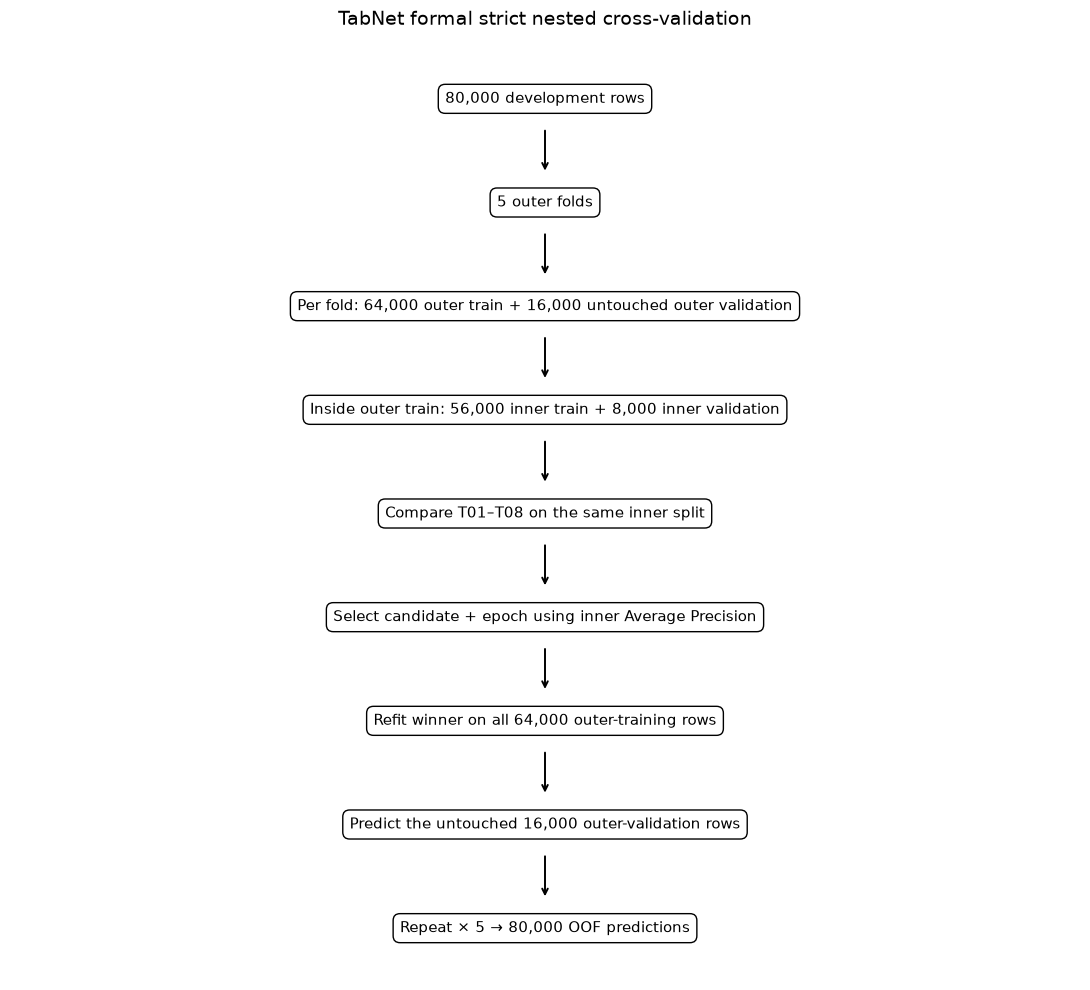

In [8]:
workflow_steps = [
    "80,000 development rows",
    "5 outer folds",
    "Per fold: 64,000 outer train + 16,000 untouched outer validation",
    "Inside outer train: 56,000 inner train + 8,000 inner validation",
    "Compare T01–T08 on the same inner split",
    "Select candidate + epoch using inner Average Precision",
    "Refit winner on all 64,000 outer-training rows",
    "Predict the untouched 16,000 outer-validation rows",
    "Repeat × 5 → 80,000 OOF predictions",
]

fig, ax = plt.subplots(figsize=(11, 10))
ax.set_xlim(0, 1)
ax.set_ylim(-0.5, len(workflow_steps) - 0.5)
ax.axis("off")
for index, step in enumerate(workflow_steps):
    y = len(workflow_steps) - 1 - index
    ax.text(0.5, y, step, ha="center", va="center", fontsize=11,
            bbox={"boxstyle": "round,pad=0.45", "facecolor": "white", "edgecolor": "black"})
    if index < len(workflow_steps) - 1:
        ax.annotate("", xy=(0.5, y - 0.72), xytext=(0.5, y - 0.28),
                    arrowprops={"arrowstyle": "->", "linewidth": 1.4})
ax.set_title("TabNet formal strict nested cross-validation", fontsize=14, pad=16)
plt.tight_layout()
plt.show()

**Interpretation:** Inner validation chooses the model; outer validation estimates generalization.

### Visual 2 — T01–T08 inner-validation comparison

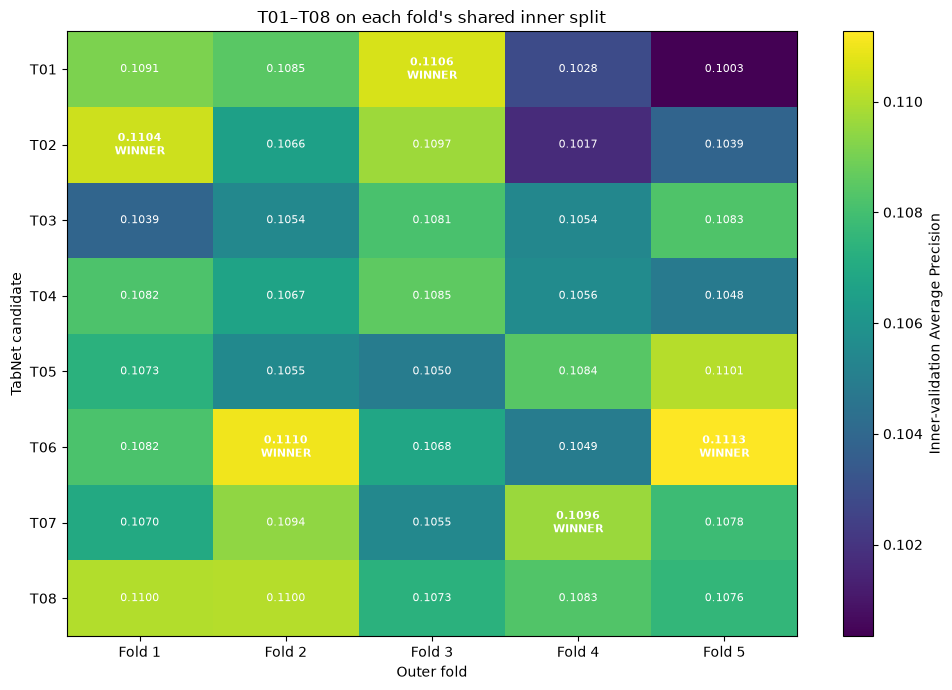

In [9]:
candidate_order = [f"T{number:02d}" for number in range(1, 9)]
fold_order = [1, 2, 3, 4, 5]
viva_ap_matrix = (
    viva_candidate_selection.pivot(
        index="candidate_id", columns="outer_fold", values="inner_average_precision"
    ).reindex(index=candidate_order, columns=fold_order)
)
assert viva_ap_matrix.shape == (8, 5) and viva_ap_matrix.notna().all().all()
selected_by_fold = viva_fold_selection.set_index("outer_fold")["selected_candidate_id"].to_dict()

fig, ax = plt.subplots(figsize=(10, 7))
image = ax.imshow(viva_ap_matrix.to_numpy(), aspect="auto")
fig.colorbar(image, ax=ax, label="Inner-validation Average Precision")
ax.set_xticks(range(len(fold_order)), [f"Fold {fold}" for fold in fold_order])
ax.set_yticks(range(len(candidate_order)), candidate_order)
for row, candidate in enumerate(candidate_order):
    for column, fold in enumerate(fold_order):
        value = viva_ap_matrix.loc[candidate, fold]
        winner_label = "\nWINNER" if selected_by_fold[fold] == candidate else ""
        ax.text(column, row, f"{value:.4f}{winner_label}", ha="center", va="center",
                fontsize=8, color="white", fontweight="bold" if winner_label else "normal")
ax.set_xlabel("Outer fold")
ax.set_ylabel("TabNet candidate")
ax.set_title("T01–T08 on each fold's shared inner split")
plt.tight_layout()
plt.show()

**Interpretation:** All eight candidates used the same inner split within each outer fold, and the highest inner-validation AP was selected.

### Visual 3 — Fold-specific winners and selected epochs

,Outer Fold,Selected Candidate,Selected Epoch
0,1,T02,33
1,2,T06,7
2,3,T01,20
3,4,T07,4
4,5,T06,2


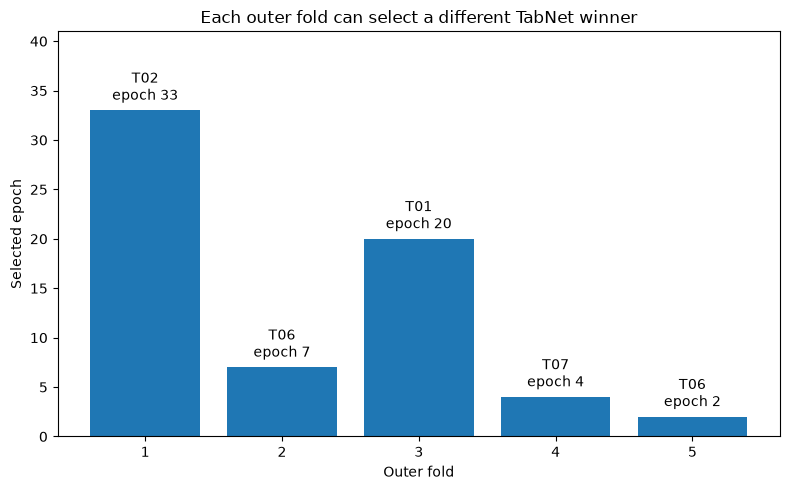

In [10]:
viva_winners = viva_fold_selection.sort_values("outer_fold").reset_index(drop=True)
expected_winner_columns = ["outer_fold", "selected_candidate_id", "selected_epoch"]
display(viva_winners[expected_winner_columns].rename(columns={
    "outer_fold": "Outer Fold",
    "selected_candidate_id": "Selected Candidate",
    "selected_epoch": "Selected Epoch",
}))

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(viva_winners["outer_fold"], viva_winners["selected_epoch"])
for bar, candidate, epoch in zip(
    bars, viva_winners["selected_candidate_id"], viva_winners["selected_epoch"]
):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.6,
            f"{candidate}\nepoch {int(epoch)}", ha="center", va="bottom")
ax.set_xticks(viva_winners["outer_fold"])
ax.set_xlabel("Outer fold")
ax.set_ylabel("Selected epoch")
ax.set_ylim(0, viva_winners["selected_epoch"].max() + 8)
ax.set_title("Each outer fold can select a different TabNet winner")
plt.tight_layout()
plt.show()

**Interpretation:** Candidate selection is fold-specific. Different folds can select different TabNet configurations because each fold contains different training and validation data.

### Visual 4 — Formal performance versus no-skill references

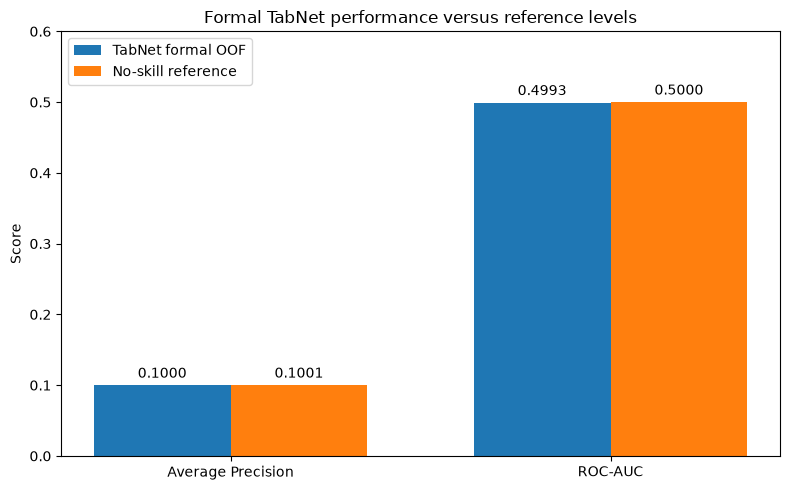

In [11]:
formal_values = [
    float(viva_summary["pooled_average_precision"]),
    float(viva_summary["pooled_roc_auc"]),
]
reference_values = [float(viva_oof["y_true"].mean()), 0.5]
metric_labels = ["Average Precision", "ROC-AUC"]
positions = np.arange(len(metric_labels))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(8, 5))
formal_bars = ax.bar(positions - bar_width / 2, formal_values, bar_width, label="TabNet formal OOF")
reference_bars = ax.bar(positions + bar_width / 2, reference_values, bar_width, label="No-skill reference")
ax.bar_label(formal_bars, fmt="%.4f", padding=3)
ax.bar_label(reference_bars, fmt="%.4f", padding=3)
ax.set_xticks(positions, metric_labels)
ax.set_ylabel("Score")
ax.set_ylim(0, 0.6)
ax.set_title("Formal TabNet performance versus reference levels")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** TabNet performance is around the no-skill reference, indicating little generalizable signal in the approved predictors.

### Visual 5 — Development OOF confusion matrix at the fixed 0.5 threshold

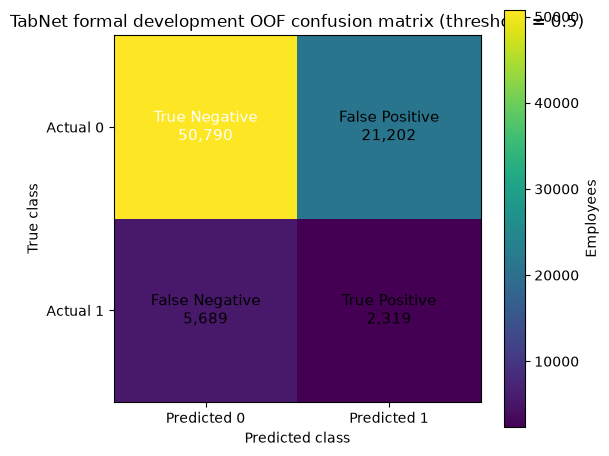

In [12]:
y_true = viva_oof["y_true"].astype(int).to_numpy()
y_pred = viva_oof["y_pred_0_5"].astype(int).to_numpy()
viva_confusion = np.array([
    [np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
    [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))],
])
assert viva_confusion.sum() == 80_000
cell_names = np.array([["True Negative", "False Positive"], ["False Negative", "True Positive"]])

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(viva_confusion)
fig.colorbar(image, ax=ax, label="Employees")
for row in range(2):
    for column in range(2):
        value = viva_confusion[row, column]
        text_colour = "white" if value > viva_confusion.max() / 2 else "black"
        ax.text(column, row, f"{cell_names[row, column]}\n{value:,}",
                ha="center", va="center", color=text_colour, fontsize=11)
ax.set_xticks([0, 1], ["Predicted 0", "Predicted 1"])
ax.set_yticks([0, 1], ["Actual 0", "Actual 1"])
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("TabNet formal development OOF confusion matrix (threshold = 0.5)")
plt.tight_layout()
plt.show()

**Interpretation:** Precision depends on true positives relative to all predicted positives, recall depends on true positives relative to all actual resignations, and F1 balances those two quantities. The threshold remains fixed at 0.5; it is not optimized here.

### Visual 6 — Saved early-stopping example

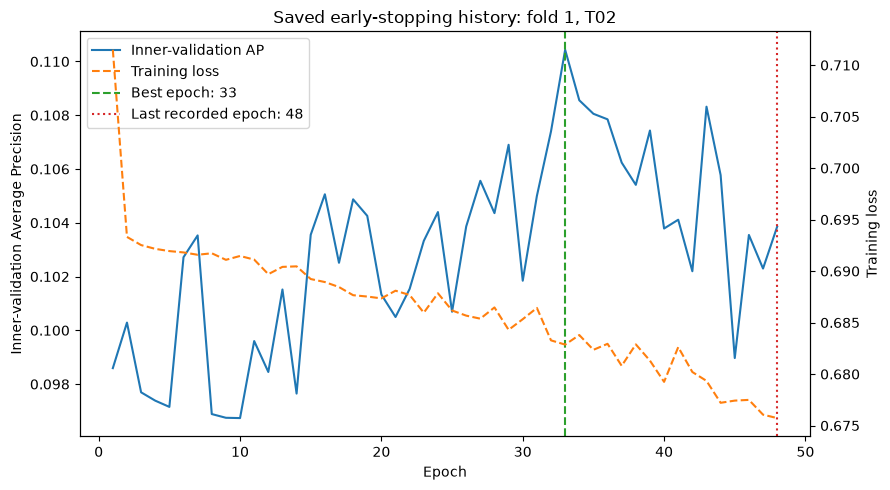

In [13]:
example_fold = 1
example_winner = viva_fold_selection.loc[
    viva_fold_selection["outer_fold"] == example_fold
].iloc[0]
example_candidate = str(example_winner["selected_candidate_id"])
example_selected_epoch = int(example_winner["selected_epoch"])
history_path = VIVA_RESULTS_DIR / "training_histories" / f"fold_{example_fold:02d}.json"
saved_histories = json.loads(history_path.read_text(encoding="utf-8"))
example_history = saved_histories[example_candidate]
inner_ap_history = np.asarray(example_history["inner_valid_average_precision"], dtype=float)
loss_history = np.asarray(example_history["loss"], dtype=float)
epochs = np.arange(1, len(inner_ap_history) + 1)
assert len(inner_ap_history) == len(loss_history)
assert int(np.nanargmax(inner_ap_history)) + 1 == example_selected_epoch

fig, ap_axis = plt.subplots(figsize=(9, 5))
loss_axis = ap_axis.twinx()
ap_line = ap_axis.plot(epochs, inner_ap_history, color="C0", label="Inner-validation AP")
loss_line = loss_axis.plot(epochs, loss_history, color="C1", linestyle="--", label="Training loss")
best_line = ap_axis.axvline(example_selected_epoch, color="C2", linestyle="--",
                            label=f"Best epoch: {example_selected_epoch}")
stop_line = ap_axis.axvline(epochs[-1], color="C3", linestyle=":",
                            label=f"Last recorded epoch: {epochs[-1]}")
ap_axis.set_xlabel("Epoch")
ap_axis.set_ylabel("Inner-validation Average Precision")
loss_axis.set_ylabel("Training loss")
ap_axis.set_title(f"Saved early-stopping history: fold {example_fold}, {example_candidate}")
lines = ap_line + loss_line + [best_line, stop_line]
ap_axis.legend(lines, [line.get_label() for line in lines], loc="best")
plt.tight_layout()
plt.show()

**Interpretation:** The best epoch comes from inner-validation AP. Training continued through the patience window before stopping; the outer-validation fold was never used to choose the epoch.